In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
df = pd.read_csv("train_u6lujuX_CVtuZ9i (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:

# Display dataset dimensions
print("Number of rows and columns:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()


Number of rows and columns: (614, 13)

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    flo

In [4]:

print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())


First five rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Last five rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [5]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Total missing values: 149


In [6]:

print("Loan approval counts:")
print(df["Loan_Status"].value_counts())

print("\nLoan approval percentages:")
print(
    (df["Loan_Status"].value_counts(normalize=True) * 100)
    .round(2)
)


Loan approval counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan approval percentages:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


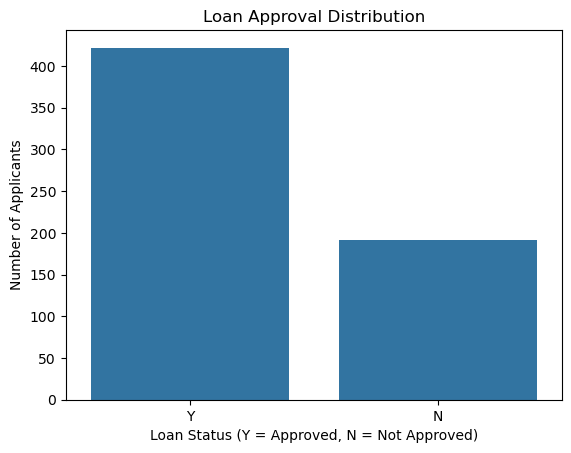

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (Y = Approved, N = Not Approved)")
plt.ylabel("Number of Applicants")
plt.show()


In [8]:

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [9]:

# Remove duplicate rows
df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)


Dataset shape after removing duplicates: (614, 13)


In [10]:

# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

# Fill missing numerical values with median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values after cleaning:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

Total missing values: 0


In [11]:

print("Cleaned dataset shape:", df.shape)
display(df.head())


Cleaned dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


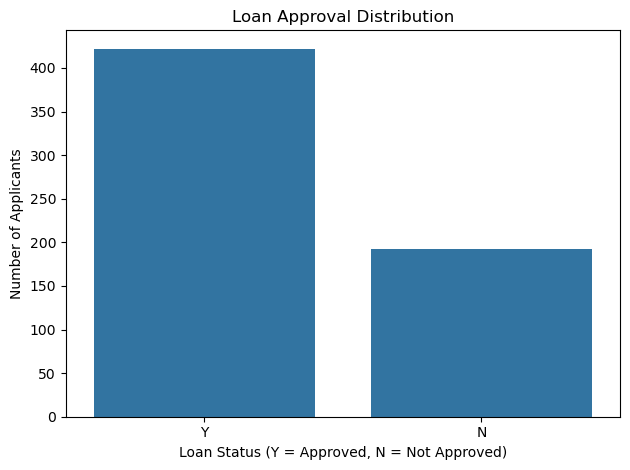

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (Y = Approved, N = Not Approved)")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()


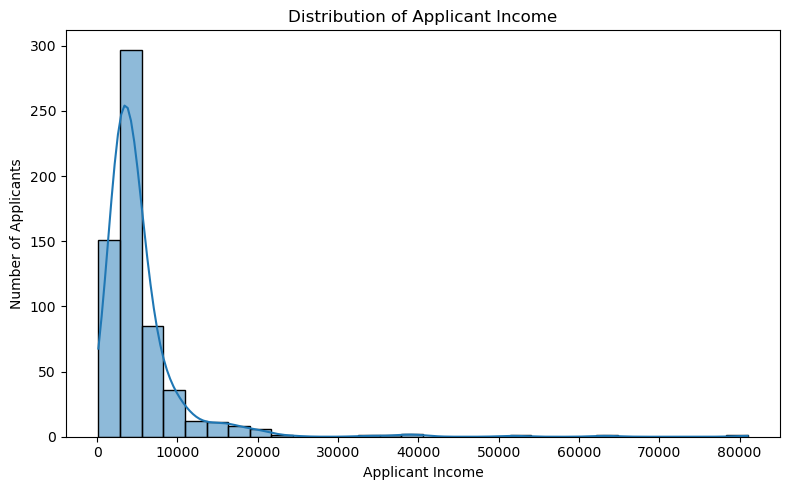

In [13]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="ApplicantIncome", bins=30, kde=True)
plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()


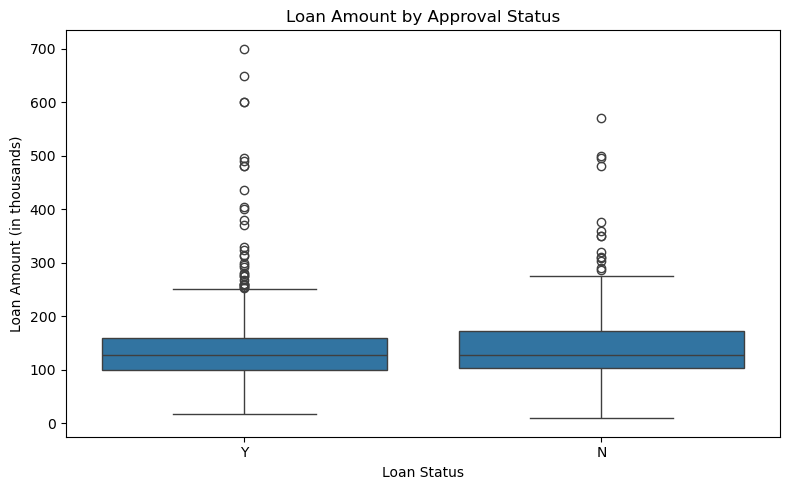

In [14]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Loan_Status", y="LoanAmount")
plt.title("Loan Amount by Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Loan Amount (in thousands)")
plt.tight_layout()
plt.show()


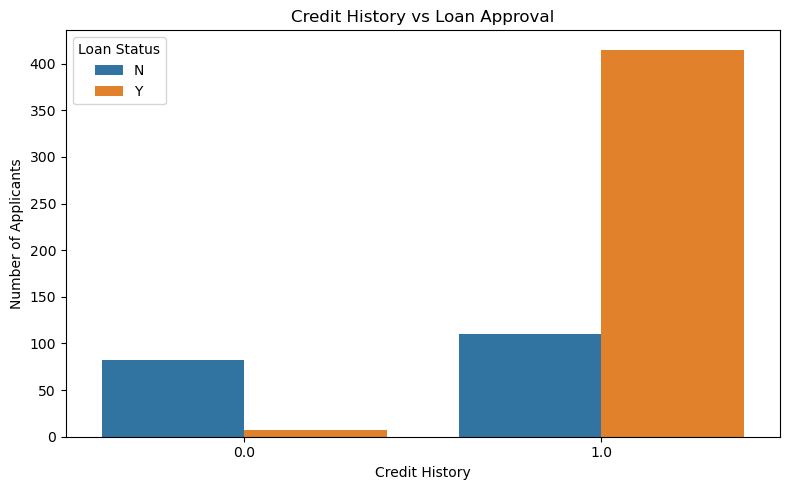

In [15]:

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Credit_History", hue="Loan_Status")
plt.title("Credit History vs Loan Approval")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()


In [16]:

# Remove the identifier column
df_model = df.drop(columns=["Loan_ID"], errors="ignore").copy()

# Separate input features and target
X = df_model.drop(columns=["Loan_Status"])
y = df_model["Loan_Status"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nInput feature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


Features (X) shape: (614, 11)
Target (y) shape: (614,)

Input feature columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Target distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [17]:

numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [18]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Preprocess numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [19]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (491, 11)
Testing features: (123, 11)
Training target: (491,)
Testing target: (123,)


In [20]:

print("Training set loan status distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting set loan status distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training set loan status distribution:
Loan_Status
Y    0.686
N    0.314
Name: proportion, dtype: float64

Testing set loan status distribution:
Loan_Status
Y    0.691
N    0.309
Name: proportion, dtype: float64


In [21]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Machine learning models imported successfully!")


Machine learning models imported successfully!


In [22]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Three model pipelines created successfully!")


Three model pipelines created successfully!


In [23]:

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully!")

print("\nAll models have been trained!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All models have been trained!


In [24]:

predictions = {}

for name, pipeline in pipelines.items():
    predictions[name] = pipeline.predict(X_test)

print("Predictions generated successfully!")

for name, prediction in predictions.items():
    print(f"{name}: {len(prediction)} predictions")


Predictions generated successfully!
Logistic Regression: 123 predictions
Decision Tree: 123 predictions
Random Forest: 123 predictions


In [25]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, pipeline in pipelines.items():
    y_pred = predictions[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="Y", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="Y", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="Y", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.862,0.840,0.988,0.908
1,Decision Tree,0.821,0.825,0.941,0.879
2,Random Forest,0.813,0.830,0.918,0.872


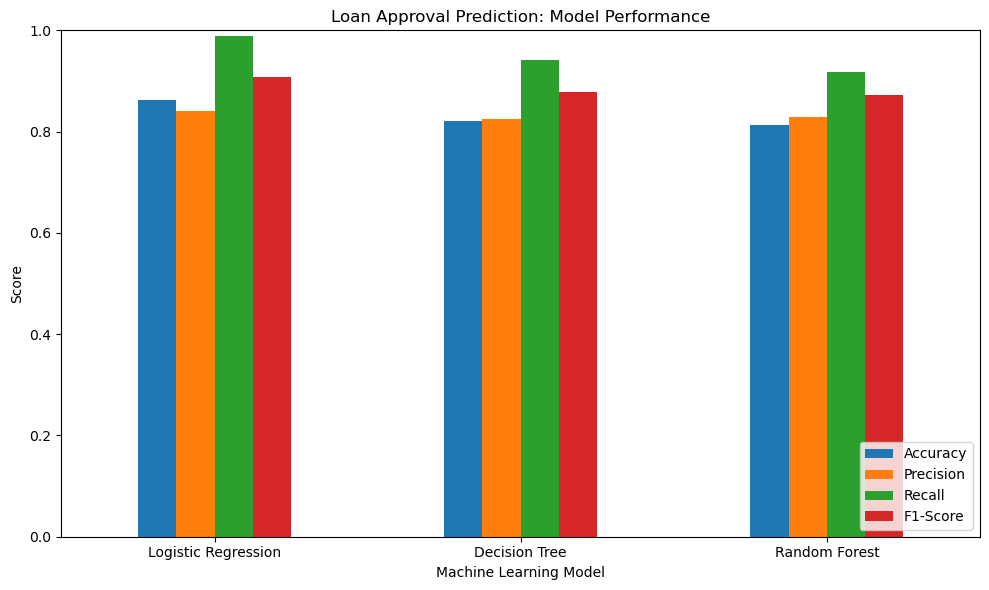

In [26]:

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Loan Approval Prediction: Model Performance")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


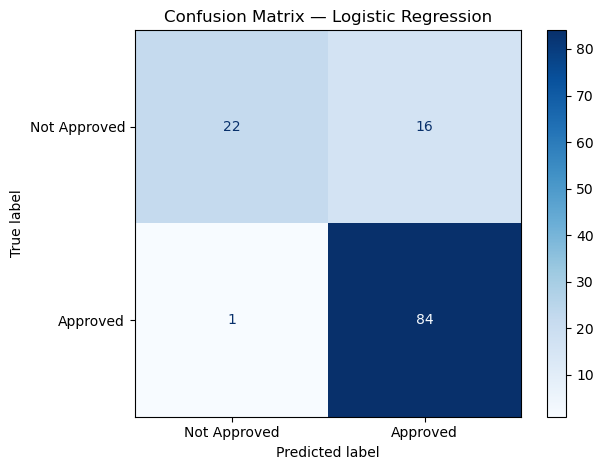

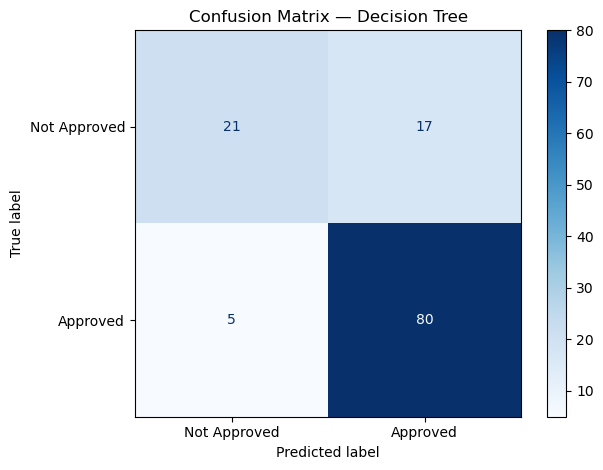

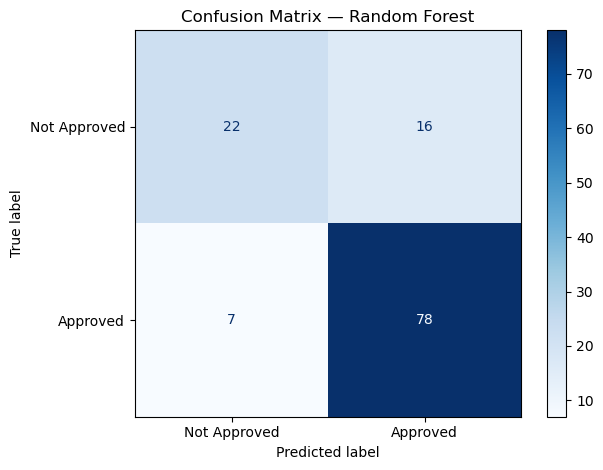

In [27]:

from sklearn.metrics import ConfusionMatrixDisplay

for name, pipeline in pipelines.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        labels=["N", "Y"],
        display_labels=["Not Approved", "Approved"],
        cmap="Blues"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()


In [28]:

for name, y_pred in predictions.items():
    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)
    print(classification_report(
        y_test,
        y_pred,
        labels=["N", "Y"],
        target_names=["Not Approved", "Approved"],
        zero_division=0
    ))



Logistic Regression
              precision    recall  f1-score   support

Not Approved       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


Decision Tree
              precision    recall  f1-score   support

Not Approved       0.81      0.55      0.66        38
    Approved       0.82      0.94      0.88        85

    accuracy                           0.82       123
   macro avg       0.82      0.75      0.77       123
weighted avg       0.82      0.82      0.81       123


Random Forest
              precision    recall  f1-score   support

Not Approved       0.76      0.58      0.66        38
    Approved       0.83      0.92      0.87        85

    accuracy                           0.81       123
   macro avg       0.79      0.75      0.76       123
weighted avg       0.81

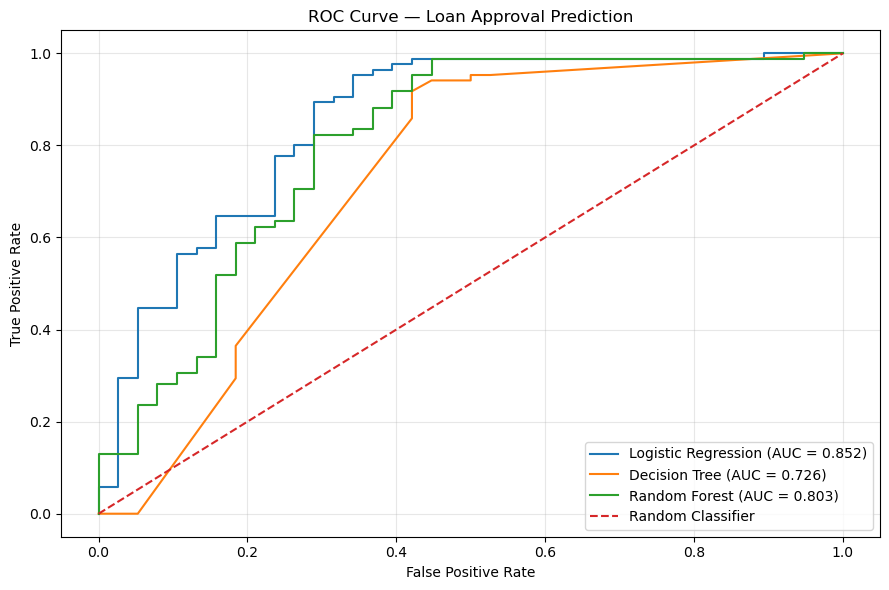

In [29]:

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, pipeline in pipelines.items():
    # Probability of loan approval (Y)
    y_probability = pipeline.predict_proba(X_test)[:, 
        list(pipeline.classes_).index("Y")
    ]

    # Convert actual labels to binary values
    y_binary = (y_test == "Y").astype(int)

    fpr, tpr, thresholds = roc_curve(y_binary, y_probability)
    auc_score = roc_auc_score(y_binary, y_probability)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random-classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve — Loan Approval Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

auc_results = []

for name, pipeline in pipelines.items():
    y_probability = pipeline.predict_proba(X_test)[:, 
        list(pipeline.classes_).index("Y")
    ]

    y_binary = (y_test == "Y").astype(int)

    auc_results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_binary, y_probability)
    })

auc_df = pd.DataFrame(auc_results)
display(auc_df.round(3))


,Model,ROC-AUC
0,Logistic Regression,0.852
1,Decision Tree,0.726
2,Random Forest,0.803


In [31]:

# Select the model with the highest F1-score
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

best_model = pipelines[best_model_name]

print("Best model:", best_model_name)
print(
    "F1-score:",
    round(
        results_df.loc[
            results_df["Model"] == best_model_name,
            "F1-Score"
        ].iloc[0],
        3
    )
)


Best model: Logistic Regression
F1-score: 0.908


In [32]:

import joblib
import os

os.makedirs("saved_models", exist_ok=True)

model_path = os.path.join(
    "saved_models",
    "loan_approval_model.pkl"
)

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved location:", os.path.abspath(model_path))


Model saved successfully!
Saved location: C:\Users\asus\OneDrive\Desktop\thiranex1\Loan_Approval_Prediction\saved_models\loan_approval_model.pkl


In [33]:

loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]

print("Model loaded successfully!")
print("Predicted loan status:", prediction)
print(
    "Prediction:",
    "Approved" if prediction == "Y" else "Not Approved"
)


Model loaded successfully!
Predicted loan status: N
Prediction: Not Approved


# Conclusion

The Loan Approval Prediction project demonstrates the application of supervised machine learning to predict loan application outcomes using applicant information.

The dataset was explored, cleaned, visualized, and prepared for modeling. Three classification algorithms—Logistic Regression, Decision Tree, and Random Forest—were trained and evaluated using accuracy, precision, recall, F1-score, confusion matrices, and ROC-AUC.

The models were compared using their evaluation results, and the selected model was saved for future predictions. This project provided practical experience in data preprocessing, feature engineering, supervised learning, and model evaluation.

**Note:** The model is intended for educational purposes and should not be used to make actual lending decisions without extensive validation and fairness assessment.

In [34]:
import os

print("Notebook project folder:", os.getcwd())
print("\nProject files:")

for item in os.listdir("."):
    print(item)

print("\nSaved model exists:",
      os.path.exists("saved_models/loan_approval_model.pkl"))

Notebook project folder: C:\Users\asus\OneDrive\Desktop\thiranex1\Loan_Approval_Prediction

Project files:
.ipynb_checkpoints
Loan_Approval_Prediction.ipynb
saved_models
train_u6lujuX_CVtuZ9i (1).csv

Saved model exists: True


In [35]:
readme = """# Loan Approval Prediction Using Machine Learning

## Project Overview
This project uses machine learning classification algorithms
to predict whether a loan application is likely to be approved.

## Technologies Used
- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Joblib

## Project Workflow
1. Dataset loading and exploration
2. Data cleaning and missing-value handling
3. Exploratory data analysis and visualization
4. Feature selection and preprocessing
5. Training and testing machine learning models
6. Model evaluation and comparison
7. ROC curve and AUC analysis
8. Saving and testing the selected model

## Models Used
- Logistic Regression
- Decision Tree
- Random Forest

## Evaluation Metrics
Accuracy, precision, recall, F1-score, confusion matrix,
and ROC-AUC.

## Disclaimer
This project is for educational purposes only and should
not be used to make real-world lending decisions.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [36]:
import os
print("README exists:", os.path.exists("README.md"))

README exists: True
